# 09 — Day 9 Evaluation: Embedding-Level Mixup on WavLM Layer 6

**Standalone**, CPU-only — no new GPU extraction needed, reuses Day 7's already-cached plain WavLM
L6 embeddings directly.

**What mixup does, precisely:** for each original recording, generate synthetic training rows by
linearly blending its embedding with another recording's embedding — `mixed = lambda * emb_A +
(1 - lambda) * emb_B` — and assigning the (shared) label to the synthetic row. This is a
fundamentally different kind of augmentation than Day 5/8a/9's speed/pitch perturbation: those
re-run the frozen model on a differently-perturbed *audio* signal; mixup never touches audio or the
model at all, it manufactures new points in the already-extracted *feature space* by interpolating
between real ones. The goal is a direct attack on the small-N problem this project diagnosed back
at Day 1 (`p >> n`, ~252 training rows against 1536+ dims) — smoothing the decision boundary rather
than betting on a specific acoustic property the way perturbation-based augmentation does.

**Design decisions, stated explicitly (same transparency as every prior day's assumptions):**
- **Pairing rule:** `A` and `B` must share both `participant_id` *and* label `y` — same person, same
  fatigue state. Never cross-participant (would blur the exact speaker-identity signal grouped CV
  exists to keep separate) and never cross-label (would invent a synthetic example with no genuine
  ground truth). Pairing *is* allowed across `activity_type` (e.g. a `read_aloud` recording mixed
  with that participant's `describe_picture` recording, same session or a different one) to maximize
  the pool of valid partners given how few recordings some participants have.
- **Blend ratio:** `lambda ~ Uniform(0.3, 0.7)`, not the classic Beta-distribution mixup formulation
  (which tends toward near-0/near-1 blends for image tasks) -- deliberately keeps every synthetic row
  a genuine blend rather than a near-copy of one parent, a reasonable first choice for embeddings
  rather than a tuned hyperparameter.
- **Volume:** 2 synthetic partners generated per original recording (each with an independently
  sampled partner and lambda), matching Day 5/8a/9's 3x pool-expansion ratio (original + 2 synthetic
  copies) for a fair comparison against the other augmentation techniques.
- **Generated once, upfront, with a fixed seed** -- not regenerated per CV fold -- same deterministic-
  augmentation-before-CV pattern as every perturbation-based augmentation notebook, so this isn't
  getting an unfair extra-averaging advantage from being re-randomized every fold.
- **Recordings with no valid same-participant/same-label partner** (a participant with only one
  recording of a given label) simply get no synthetic partners -- not an error, just fewer synthetic
  rows for that recording.

**Leakage safety, same reasoning as `is_original` masking everywhere else:** synthetic rows are
built entirely from one participant's own data and only ever enrich training pools -- never scored
as an outer-test or inner-validation row.

**Scope, stated up front:** tested isolated only (no PCA, no session-fusion) -- keeping this to one
clean variable, consistent with "test one variable at a time." If this helps, combining it with
fusion becomes a natural follow-up, not baked in here.

**No permutation test here** — reserved for Day 10's single finalized candidate.

**Inputs needed (Kaggle "Add Input") — 2 total:**
1. The **`Fatigue_data`** dataset — for `labels.csv`.
2. **Day 7's `07_features_wavlm.ipynb`** output — for `wavlm_base_plus_all_layers.parquet`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42
LAYER = 6
N_MIXUP_PER_RECORDING = 2
LAMBDA_LOW, LAMBDA_HIGH = 0.3, 0.7

LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
WAVLM_ALL_LAYERS_PARQUET = next(Path("/kaggle/input").rglob("wavlm_base_plus_all_layers.parquet"))

print(f"LABELS_CSV               = {LABELS_CSV}")
print(f"WAVLM_ALL_LAYERS_PARQUET = {WAVLM_ALL_LAYERS_PARQUET}")

LABELS_CSV               = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
WAVLM_ALL_LAYERS_PARQUET = /kaggle/input/notebooks/tapudatta/notebook1-day7/features/wavlm_base_plus_all_layers.parquet


## 1. Load Plain WavLM L6 Embeddings

In [2]:
labels = pd.read_csv(LABELS_CSV)
wavlm_all_layers = pd.read_parquet(WAVLM_ALL_LAYERS_PARQUET)

layer_cols = [c for c in wavlm_all_layers.columns if c.startswith(f"layer{LAYER}_emb_")]
assert len(layer_cols) == 1536, f"expected 1536 layer-{LAYER} columns, got {len(layer_cols)}"
wavlm_emb_only = wavlm_all_layers[["filename"] + layer_cols].copy()
wavlm_emb_only.columns = ["filename"] + [f"emb_{i}" for i in range(1536)]

df = labels.merge(wavlm_emb_only, on="filename", how="inner").reset_index(drop=True)
assert len(df) == 280, f"expected 280 rows after merge, got {len(df)}"

LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}
df["y"] = df["label"].map(LABEL_MAP)
assert df["y"].isna().sum() == 0

emb_cols = [c for c in df.columns if c.startswith("emb_")]
print(f"{len(df)} recordings, {df['participant_id'].nunique()} participants")

280 recordings, 14 participants


## 2. Generate Synthetic Mixup Rows

Built once, upfront, with a fixed seed — see the design decisions above.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)

mixup_rows = []
for (participant, label_val), group in df.groupby(["participant_id", "y"]):
    if len(group) < 2:
        continue  # no same-participant/same-label partner available -- skip, not an error
    group_idx = group.index.to_numpy()
    group_embs = group[emb_cols].to_numpy(dtype=float)

    for local_i, row_idx in enumerate(group_idx):
        for _ in range(N_MIXUP_PER_RECORDING):
            partner_choices = [j for j in range(len(group_idx)) if j != local_i]
            partner_local = rng.choice(partner_choices)
            lam = rng.uniform(LAMBDA_LOW, LAMBDA_HIGH)
            mixed_emb = lam * group_embs[local_i] + (1 - lam) * group_embs[partner_local]
            mixup_rows.append({
                "participant_id": participant,
                "y": int(label_val),
                "features": mixed_emb,
            })

mixup_df = pd.DataFrame(mixup_rows)
print(f"Generated {len(mixup_df)} synthetic mixup rows from {len(df)} originals "
      f"({len(mixup_df) / len(df):.2f}x expansion, target ~{N_MIXUP_PER_RECORDING}x).")

Generated 560 synthetic mixup rows from 280 originals (2.00x expansion, target ~2x).


## 3. Combine Original + Synthetic Rows

In [4]:
X_original = df[emb_cols].to_numpy()
y_original = df["y"].to_numpy()
groups_original = df["participant_id"].to_numpy()

X_mixup = np.vstack(mixup_df["features"].to_numpy())
y_mixup = mixup_df["y"].to_numpy()
groups_mixup = mixup_df["participant_id"].to_numpy()

X = np.vstack([X_original, X_mixup])
y = np.concatenate([y_original, y_mixup])
groups = np.concatenate([groups_original, groups_mixup])
is_original = np.concatenate([np.ones(len(df), dtype=bool), np.zeros(len(mixup_df), dtype=bool)])

print(f"Total rows: {len(X)} ({len(df)} original + {len(mixup_df)} synthetic)")
print(f"X: {X.shape}")

Total rows: 840 (280 original + 560 synthetic)
X: (840, 1536)


## 4. Shared Candidates & Augmentation-Aware Nested CV (duplicated from `06_evaluate_combined.ipynb`)

Same `nested_loso_cv_augmented_variant` used for every perturbation-based augmentation day —
synthetic rows enrich training pools only, every scored fold uses original rows only. Plain
10-candidate set, no PCA (same rationale as `09_evaluate_wavlm_pitchshift.ipynb`).

In [5]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline(model_name: str, c: float) -> Pipeline:
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


def make_candidates():
    return [
        (f"{name}_C={c}", build_pipeline(name, c))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

In [6]:
def nested_loso_cv_augmented_variant(X, y, groups, is_original, make_candidates_fn,
                                      n_inner_splits=6, expected_n_scored=None):
    participants = np.unique(groups)
    oof_scores = np.full(len(y), np.nan)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        outer_test_mask = (groups == test_participant) & is_original
        outer_train_mask = groups != test_participant
        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        is_orig_tr = is_original[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates_fn()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            inner_val_idx = inner_val_idx[is_orig_tr[inner_val_idx]]
            if len(inner_val_idx) == 0:
                continue
            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_label, best_template = candidates[best_i]

        final_pipe = clone(best_template).fit(X_tr, y_tr)
        test_scores = score_fn(final_pipe, X_te)
        oof_scores[np.where(outer_test_mask)[0]] = test_scores

        fold_records.append({"test_participant": test_participant, "chosen_label": best_label,
                              "inner_cv_auc": mean_aucs[best_i]})

    print(f"  Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    n_scored = int(np.sum(~np.isnan(oof_scores)))
    print(f"  Scored {n_scored} original rows.")
    if expected_n_scored is not None:
        assert n_scored == expected_n_scored, f"expected {expected_n_scored} scored rows, got {n_scored}"
    return oof_scores, pd.DataFrame(fold_records)


def bootstrap_auc_ci(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}
    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))
    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)


def summarize(y, oof_scores, groups):
    valid = ~np.isnan(oof_scores)
    y_v, s_v, g_v = y[valid], oof_scores[valid], groups[valid]
    auc = roc_auc_score(y_v, s_v)
    lo, hi, _ = bootstrap_auc_ci(g_v, y_v, s_v)
    return auc, lo, hi, int(valid.sum())

## 5. Run — Mixup-Augmented WavLM L6 (isolated)

In [7]:
oof_scores, fold_info = nested_loso_cv_augmented_variant(
    X, y, groups, is_original, make_candidates, expected_n_scored=280,
)
auc, ci_lo, ci_hi, n_scored = summarize(y, oof_scores, groups)
print(f"\nMixup-augmented WavLM L6: Pooled AUC = {auc:.3f}  (95% CI [{ci_lo:.3f}, {ci_hi:.3f}], N={n_scored})")
print("Reference -- Day 7 plain WavLM L6: AUC 0.663, CI [0.600, 0.710]")
print("Reference -- Day 8a speed-augmented WavLM L6: AUC 0.643, CI [0.590, 0.701]")

results_df = pd.DataFrame([
    {"variant": "Plain WavLM L6 (Day 7 reference)", "auc": 0.663, "ci_lo": 0.600, "ci_hi": 0.710},
    {"variant": "Speed-augmented WavLM L6 (Day 8a reference)", "auc": 0.643, "ci_lo": 0.590, "ci_hi": 0.701},
    {"variant": "Mixup-augmented WavLM L6", "auc": auc, "ci_lo": ci_lo, "ci_hi": ci_hi},
])
print(results_df.to_string(index=False))

  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 280 original rows.

Mixup-augmented WavLM L6: Pooled AUC = 0.655  (95% CI [0.584, 0.711], N=280)
Reference -- Day 7 plain WavLM L6: AUC 0.663, CI [0.600, 0.710]
Reference -- Day 8a speed-augmented WavLM L6: AUC 0.643, CI [0.590, 0.701]
                                    variant      auc    ci_lo    ci_hi
           Plain WavLM L6 (Day 7 reference) 0.663000 0.600000 0.710000
Speed-augmented WavLM L6 (Day 8a reference) 0.643000 0.590000 0.701000
                   Mixup-augmented WavLM L6 0.655363 0.583512 0.710864


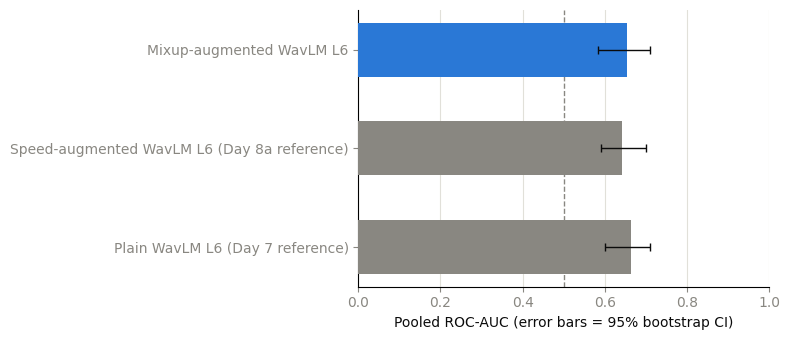

No permutation test run here -- reserved for Day 10's final buffer.


In [8]:
COLORS = ["#898781", "#898781", "#2a78d6"]  # neutral for references, blue highlight for today's result
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 3.5))
y_pos = np.arange(len(results_df))
ax.barh(y_pos, results_df["auc"], color=COLORS, height=0.55, zorder=3)
ax.errorbar(
    results_df["auc"], y_pos,
    xerr=[results_df["auc"] - results_df["ci_lo"], results_df["ci_hi"] - results_df["auc"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(results_df["variant"], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
print("No permutation test run here -- reserved for Day 10's final buffer.")

## How to read Day 9's mixup results

- **Beats Day 7's plain WavLM L6 (0.663) clearly**, CI lower bound moving up too: the small-N
  smoothing bet paid off where the two perturbation-based augmentations (speed, pitch) didn't --
  worth re-ensembling with plain HuBERT (Day 8b's recipe) to see if it pushes past 0.676/0.678.
- **Close to 0.663 with heavily overlapping CIs, or below it**: mixup doesn't help WavLM either --
  three different augmentation mechanisms (speed, pitch, mixup) all failing to improve on plain
  WavLM L6 would be a strong, honest signal that this specific embedding's signal is already
  well-captured by the 280 real recordings, and further synthetic data isn't the lever that helps
  it. Carry Day 7's plain WavLM L6 forward as the WavLM-family entry into Day 10.

**No permutation test yet.** Update `PROJECT_PLAN.md`'s Day 7+ roadmap section with today's number,
then decide what (if anything, across pitch-shift and mixup) advances to a re-ensembling step
before Day 10's final buffer.